# Season tyre degradation, 2025 dry races

I want to know if a model that includes tyre age predicts the rest of a race better than a model that does not. This notebook runs that test on the 2025 Grand Prix data and reads the results from `results/`.

A stint is the run of laps a driver does between pit stops. Each stint is on one compound (SOFT, MEDIUM or HARD). Tyre age is the number of laps the set has been used. Within one stint, tyre age and race lap number go up together by one every lap. Worn tyres make the car slower. Burning fuel and a rubbered-in track make it faster. From one stint these cannot be separated. Across a race they can, because drivers pit on different laps, so at the same race lap different cars have tyres of different ages. The models below use that. No fuel number is assumed. The effect of fuel and track is estimated as the coefficient on race lap number.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import config as cfg
import f1deg as F
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"SOFT": "#c0392b", "MEDIUM": "#d4a017", "HARD": "#555555", "M0": "#7f8c8d", "M1": "#1f77b4", "M2": "#e67e22"}
races = pd.read_csv("results/races.csv")
summ = pd.read_csv("results/summary.csv").set_index("metric")["value"]
val = pd.read_csv("results/validation.csv")
fits = pd.read_csv("results/full_race_fits.csv")
stints = pd.read_csv("results/stints.csv")


## 1. Data

In [2]:
print(races["status"].value_counts().to_string())
print()
print("Wet races:", ", ".join(races.loc[races.status == "wet", "EventName"]))
print("Validation-eligible races:", int(summ["validation_eligible_races"]))
print()
print(races.loc[~races.eligible, ["Round", "EventName", "status", "reason"]].to_string(index=False))
fc = pd.read_csv("results/filter_counts.csv")
tot = fc.drop(columns=["Round", "EventName"]).sum()
print()
print(tot.to_string())

status
used    21
wet      3

Wet races: Australian Grand Prix, British Grand Prix, Belgian Grand Prix
Validation-eligible races: 19

 Round              EventName status                  reason
     1  Australian Grand Prix    wet                wet race
     6       Miami Grand Prix   used    train laps 187 < 200
    12     British Grand Prix    wet                wet race
    13     Belgian Grand Prix    wet                wet race
    20 Mexico City Grand Prix   used M0 design not full rank

raw_laps                    24058
s1_laptime_notnull          24033
s2_lap_ge_2                 23623
s3_no_pit                   22309
s4_green                    20790
s5_accurate                 20770
s6_dry_compound_tyrelife    20461
s7_not_slow                 19324


The table above sums the laps that survive each clean-lap step over all dry races. Races that were not eligible for the forecast test are listed with their reason.

## 2. The confound shown with data

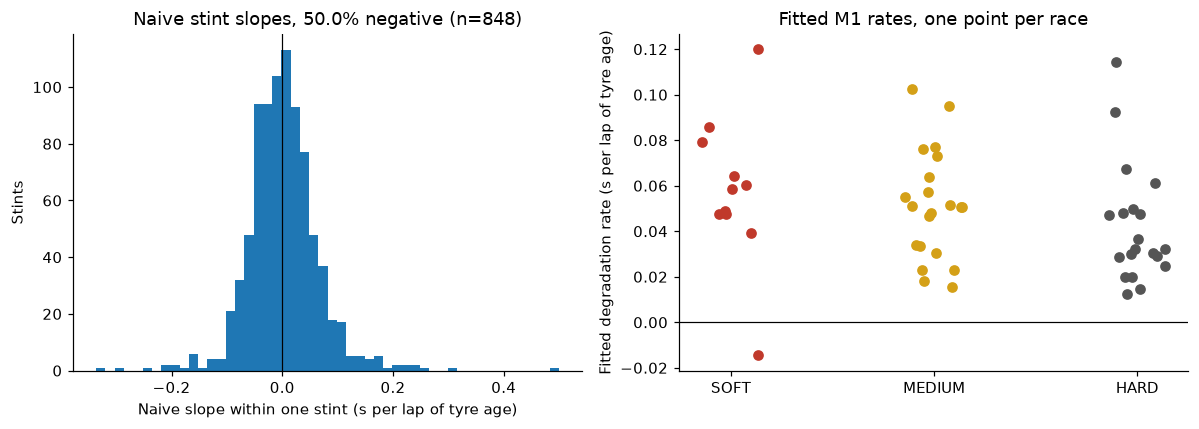

Median naive slope: -0.0
Median fitted rate by compound:
Compound
HARD      0.0321
MEDIUM    0.0507
SOFT      0.0584


In [3]:
share_neg = (stints["naive_slope"] < 0).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
ax[0].hist(stints["naive_slope"].clip(-0.5, 0.5), bins=50, color="#1f77b4")
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set_xlabel("Naive slope within one stint (s per lap of tyre age)")
ax[0].set_ylabel("Stints")
ax[0].set_title(f"Naive stint slopes, {share_neg:.1%} negative (n={len(stints)})")
for c in cfg.DRY_COMPOUNDS:
    s = fits.loc[fits.Compound == c, "deg_rate"]
    ax[1].scatter(np.full(len(s), cfg.DRY_COMPOUNDS.index(c)) + np.random.default_rng(1).uniform(-0.15, 0.15, len(s)), s, color=COL[c])
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(cfg.DRY_COMPOUNDS)
ax[1].set_ylabel("Fitted degradation rate (s per lap of tyre age)")
ax[1].set_title("Fitted M1 rates, one point per race")
fig.tight_layout(); fig.savefig("Images/naive_vs_fitted.png", dpi=150, bbox_inches="tight"); plt.show()
print("Median naive slope:", round(stints["naive_slope"].median(), 4))
print("Median fitted rate by compound:")
print(fits.groupby("Compound")["deg_rate"].median().round(4).to_string())

A naive slope uses one stint and ignores fuel and track evolution. Those effects push lap times down at the same time as tyre wear pushes them up, so the naive slope mixes both and often sits near zero or below it. The fitted rates come from the model that has a separate lap-number term, so they are the part of the lap-time trend that goes with tyre age under this model. The histogram and the point plot above show the difference.

## 3. Full-race fits

Compound                     HARD  MEDIUM    SOFT
EventName                                        
Abu Dhabi Grand Prix       0.0478  0.0948     NaN
Austrian Grand Prix        0.0477  0.0550 -0.0145
Azerbaijan Grand Prix      0.0124  0.0154     NaN
Bahrain Grand Prix         0.1142  0.1024  0.1199
Canadian Grand Prix        0.0200  0.0730     NaN
Chinese Grand Prix         0.0366  0.0770     NaN
Dutch Grand Prix           0.0304  0.0304  0.0475
Emilia Romagna Grand Prix  0.0497  0.0467     NaN
Hungarian Grand Prix       0.0471  0.0516  0.0476
Italian Grand Prix         0.0147  0.0182     NaN
Japanese Grand Prix        0.0321  0.0507  0.0584
Las Vegas Grand Prix       0.0301  0.0338     NaN
Mexico City Grand Prix     0.0321  0.0512  0.0645
Miami Grand Prix           0.0674  0.0763     NaN
Monaco Grand Prix          0.0289  0.0230     NaN
Qatar Grand Prix           0.0287  0.0336  0.0605
Saudi Arabian Grand Prix   0.0248  0.0505     NaN
Singapore Grand Prix       0.0614  0.0231  0.0392


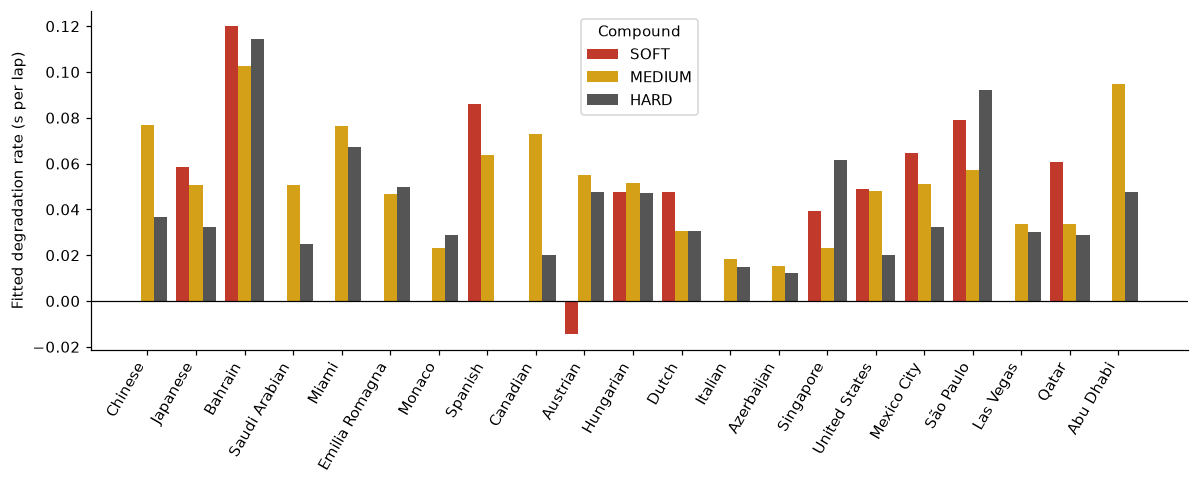

In [4]:
tab = fits.pivot(index="EventName", columns="Compound", values="deg_rate").round(4)
lc = fits.drop_duplicates("Round").set_index("EventName")[["lap_coef", "lap_coef_se", "r2", "resid_sd", "n_laps"]].round(4)
print(tab.to_string()); print(); print(lc.to_string())
order = fits.drop_duplicates("Round")["EventName"].tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.27
for i, c in enumerate(cfg.DRY_COMPOUNDS):
    s = tab[c].reindex(order)
    ax.bar(np.arange(len(order)) + (i - 1) * w, s.values, width=w, color=COL[c], label=c)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace(" Grand Prix", "") for o in order], rotation=60, ha="right")
ax.set_ylabel("Fitted degradation rate (s per lap)"); ax.legend(title="Compound")
fig.tight_layout(); fig.savefig("Images/deg_by_race.png", dpi=150, bbox_inches="tight"); plt.show()

SOFT, MEDIUM and HARD are different physical tyres at different races, so these rates are not comparable across races as if they were the same tyre. They are fitted degradation rates under this model, not the true tyre degradation. The lap-number coefficient is the combined effect of fuel burn and track evolution in seconds per race lap.

## 4. The forecast test

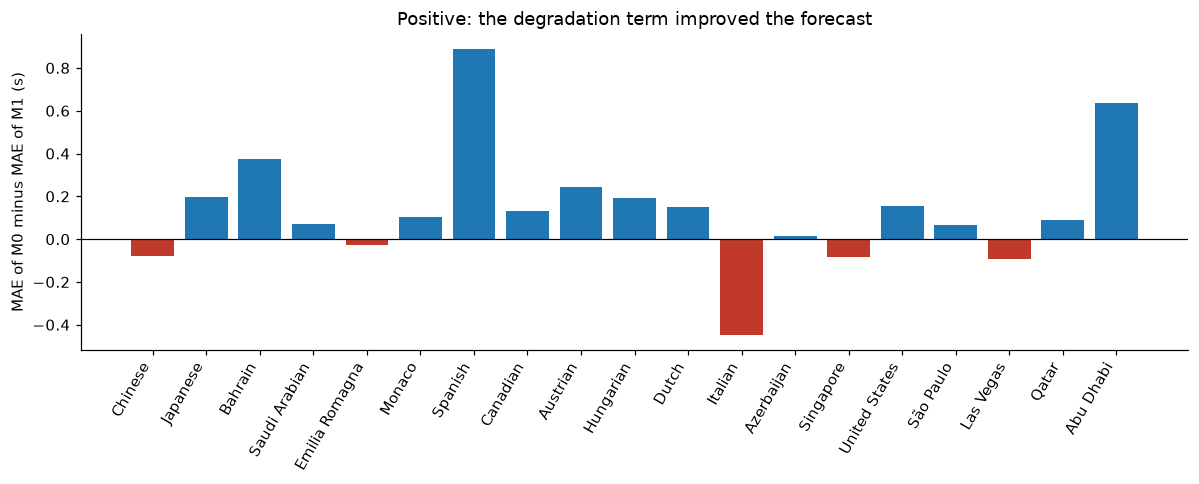

D1 = 0.1362 s, indicative interval [0.0174, 0.2689]
Races where M1 beat M0: 14 of 19
Pooled test MAE: M0 0.7803, M1 0.6398, M2 0.7090


In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
lab = val["EventName"].str.replace(" Grand Prix", "")
ax.bar(lab, val["MAE_M0_minus_M1"], color=np.where(val["MAE_M0_minus_M1"] > 0, "#1f77b4", "#c0392b"))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("MAE of M0 minus MAE of M1 (s)"); plt.xticks(rotation=60, ha="right")
ax.set_title("Positive: the degradation term improved the forecast")
fig.tight_layout(); fig.savefig("Images/forecast_gain_by_race.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"D1 = {summ['D1']:.4f} s, indicative interval [{summ['D1_lo']:.4f}, {summ['D1_hi']:.4f}]")
print(f"Races where M1 beat M0: {int(summ['races_M1_beat_M0'])} of {int(summ['validation_eligible_races'])}")
print(f"Pooled test MAE: M0 {summ['pooled_test_MAE_M0']:.4f}, M1 {summ['pooled_test_MAE_M1']:.4f}, M2 {summ['pooled_test_MAE_M2']:.4f}")

In [6]:
d1, lo, hi = summ["D1"], summ["D1_lo"], summ["D1_hi"]
if lo > 0:
    verdict = "In these races the model with a tyre degradation term forecast the rest of the race better than the model without one, and the indicative interval is above zero."
elif hi < 0:
    verdict = "In these races the model with a tyre degradation term forecast worse than the model without one."
else:
    verdict = "The indicative interval for D1 includes zero, so these races do not settle whether the degradation term helped."
print(verdict)

In these races the model with a tyre degradation term forecast the rest of the race better than the model without one, and the indicative interval is above zero.


The cell above states the answer to the research question from the computed interval. The unit of resampling is the race, because laps inside a race are not independent. A few individual races go the other way in the bar chart. With this few races those are observations, not findings.

## 5. Linear or quadratic

In [7]:
print(f"D2 = {summ['D2']:.4f} s, indicative interval [{summ['D2_lo']:.4f}, {summ['D2_hi']:.4f}]")
print(f"Races where M2 beat M1: {int(summ['races_M2_beat_M1'])} of {int(summ['validation_eligible_races'])}")
print(pd.DataFrame({m: [summ[f"pooled_test_bias_{m}"], summ[f"pooled_test_MAE_{m}"], summ[f"pooled_test_RMSE_{m}"]] for m in F.MODELS},
                   index=["bias (pred - actual)", "MAE", "RMSE"]).round(4).to_string())

D2 = -0.0715 s, indicative interval [-0.1341, -0.0215]
Races where M2 beat M1: 4 of 19
                          M0      M1      M2
bias (pred - actual)  0.2464 -0.0495 -0.0982
MAE                   0.7803  0.6398  0.7090
RMSE                  1.0542  0.9040  1.0017


D2 is positive when the quadratic term helps. The numbers above show whether it did. Bias is predicted minus actual lap time, so a positive bias means the model predicts laps slower than they were.

## 6. Forecast horizon

bucket  laps  MAE_M0  MAE_M1  MAE_M2
   1-5  1619  0.6059  0.4716  0.4994
  6-10  1478  0.7101  0.5293  0.6000
 11-20  3070  0.8218  0.6759  0.7736
   21+  1365  0.9699  0.8780  0.9305


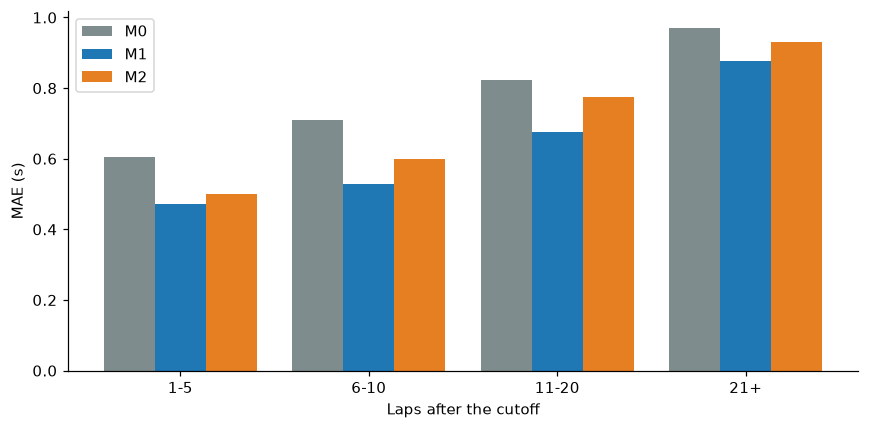

In [8]:
hz = pd.read_csv("results/horizon.csv")
print(hz.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(hz)); w = 0.27
for i, m in enumerate(F.MODELS):
    ax.bar(x + (i - 1) * w, hz[f"MAE_{m}"], width=w, color=COL[m], label=m)
ax.set_xticks(x); ax.set_xticklabels(hz["bucket"]); ax.set_xlabel("Laps after the cutoff"); ax.set_ylabel("MAE (s)"); ax.legend()
fig.tight_layout(); fig.savefig("Images/mae_by_horizon.png", dpi=150, bbox_inches="tight"); plt.show()

Error is pooled over all validation-eligible races. The table shows how the error of each model changes with the number of laps after the cutoff.

## 7. Sensitivity checks

In [9]:
print(pd.read_csv("results/sensitivity_train_fraction.csv").round(4).to_string(index=False))
print()
print(pd.read_csv("results/sensitivity_clean_air.csv").round(4).to_string(index=False))

 train_fraction  n_eligible     D1   D1_lo  D1_hi      D2   D2_lo   D2_hi
            0.5          19 0.1964 -0.0081 0.3934 -0.1501 -0.2738 -0.0539
            0.6          19 0.1362  0.0174 0.2689 -0.0715 -0.1341 -0.0215
            0.7          21 0.1039  0.0354 0.1800 -0.0317 -0.0731  0.0048

 train_fraction  n_eligible     D1  D1_lo  D1_hi      D2   D2_lo  D2_hi
            0.6          17 0.1613 0.0238 0.3133 -0.0994 -0.3025 0.0286


These are checks on a design that was fixed before the data was seen. They are not a search for a better setting. The primary result stays at a train fraction of 0.60 with all clean laps.

## 8. Exploratory: track temperature

In [10]:
m = fits.merge(races[["Round", "mean_track_temp"]], on="Round")
for c in ["MEDIUM", "HARD"]:
    s = m[m.Compound == c]
    rho, p = spearmanr(s["mean_track_temp"], s["deg_rate"])
    print(f"{c}: Spearman rho = {rho:.3f}, p = {p:.3f}, races = {len(s)}")

MEDIUM: Spearman rho = 0.192, p = 0.404, races = 21
HARD: Spearman rho = -0.080, p = 0.738, races = 20


This is exploratory. The correlations above are computed over a small number of races and the compounds are different tyres at each race. No claim is made from it.

## 9. What this shows and what it does not

This shows that, over the validation-eligible dry races of 2025, adding a linear tyre age term to a model with driver, compound and race lap effects lowered the pooled forecast error. The quadratic term did not improve on the linear one in the pooled numbers. The sensitivity tables use other cutoffs and the clean-air subset and are read as checks only.

It does not show the true physical degradation of any tyre. Lap times reflect the pace drivers chose, so the fitted rates include tyre management. The lap-number term absorbs fuel burn, track evolution and anything else that moves steadily through a race, and these are not separated from each other. Fuel loads, engine modes and tyre temperatures are not public. Dirty air is handled only by the clean-air check. About twenty dry races from one season is a small sample, and the individual races in the bar chart are observations, not findings.